# Gaussian mixtures and EM: likelihood, latent variables, and lower bounds

## 1. Introduction and learning objectives

A mixture model explains observations through a latent component and an explicit probability distribution. It can express overlapping ellipses that a squared-distance partition cannot. Its posterior responsibilities quantify assignments under that model; they do not certify semantic categories or uncertainty about estimated parameters. Learning a density, recovering a latent explanation and finding a useful representation are separate claims.

Build a stable Gaussian mixture, derive and implement expectation-maximization (EM), independently check likelihood derivatives and bound identities, and investigate covariance assumptions and collapse. The lower-bound argument is also preparation for Bayesian/variational inference and later generative models. Work remains manual NumPy; linear solves, Cholesky factors and symmetric eigensolvers are numerical primitives. No framework, data download or GPU is required.

**Prerequisites:** Stage 00 probability, covariance, matrix calculus and log-domain computation; Stage 01 experimental design. The preceding clustering chapter is helpful for initialization and geometry, but this notebook requires none of its live functions. Rows are observations, $X\in\mathbb R^{n\times d}$. All likelihoods below are **averages of natural log densities** unless a sum is explicitly stated.

## 2. Prerequisites and mathematical foundations

Let $z_i\in\{0,\ldots,k-1\}$ be a latent categorical variable, with weights $\pi_j>0$ summing to one. Conditional on $z_i=j$, assume $x_i\sim\mathcal N(\mu_j,\Sigma_j)$, where $\mu_j\in\mathbb R^d$ and $\Sigma_j$ is symmetric positive definite. With independent identically distributed observations, the average observed log-likelihood is
$$\ell(\theta)=\frac1n\sum_i\log\sum_j\pi_j\mathcal N(x_i;\mu_j,\Sigma_j).$$
A density can exceed one and depends on coordinate units. An integrated density gives a probability; its value at a point is not a discrete class probability. Comparing densities after a change of coordinates requires the corresponding Jacobian, not an unqualified comparison of numeric log scores.

Define the log joint $a_{ij}=\log\pi_j+\log\mathcal N(x_i;\mu_j,\Sigma_j)$. Compute $\log p(x_i)=m_i+\log\sum_j\exp(a_{ij}-m_i)$, where $m_i=\max_j a_{ij}$. The **E-step** is Bayes' rule:
$$r_{ij}=p(z_i=j\mid x_i,\theta)=\exp\big(a_{ij}-\log p(x_i)\big).$$
Responsibilities have shape $(n,k)$ and each row sums to one. Their logarithms should be computed directly from log joints, because exponentiating very negative entries can give zero. That numerical zero does not make the mathematical component impossible.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.02.01 — Separate the observed, latent, and parameter quantities

**Type:** Conceptual · **Answer:** Markdown

Specify the shapes and meanings of $X,z,\pi,\mu,\Sigma,r$. Explain how a mixture differs from a Gaussian classifier with observed class labels. What does a responsibility near one establish, and why can neither a density value nor a responsibility be read as uncertainty about all fitted parameters?

**Expected outcome:** a generative story, correct shapes, and clear boundaries between latent-assignment probability, parameter uncertainty and scientific interpretation.

**Your response to Exercise 03.02.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.01**

In this notebook the parameters are point estimates. The posterior is over the component of an observation conditional on those estimates.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.01**

The data have shape $(n,d)$; latent IDs shape $(n,)$; weights $(k,)$; means $(k,d)$; covariances $(k,d,d)$; and responsibilities $(n,k)$. A Gaussian classifier fits class-conditional distributions using observed labels. Here component membership is hidden and is estimated jointly with point-valued parameters. A responsibility near one means one component dominates for that observation under the fitted model. It does not prove a semantic class, a reliable model or precise parameter estimates. Label permutation leaves the density unchanged. Densities depend on units and may exceed one, whereas responsibilities are normalized conditional probabilities over components.

</details>

## 3. Theoretical development and worked examples

### From Jensen to an exact gap identity

For arbitrary categorical rows $q_i$, define
$$\mathcal F(q,\theta)=\frac1n\sum_{i,j}q_{ij}\big(a_{ij}-\log q_{ij}\big),$$
with $0\log0=0$. Applying concavity of log gives a lower bound, $\mathcal F\le\ell$. For rows with zero entries, Jensen applied on their positive support can omit positive joint mass; the bound still holds, but that intermediate equality needs the support qualification. The more direct identity avoids hiding it:
$$\ell(\theta)-\mathcal F(q,\theta)=\frac1n\sum_i\mathrm{KL}\big(q_i\,\|\,r_i(\theta)\big)\ge0.$$
Substitute $\log r_{ij}=a_{ij}-\log p(x_i)$ into the KL definition to derive every term. Our positive weights and positive Gaussian densities ensure the true posterior has full support. Equality holds exactly when each $q_i$ is that posterior. The bound is a function of both the auxiliary distributions and the model parameters, not a replacement observed-data likelihood.

Exact EM sets $q=r(\theta^{old})$, then increases the same bound in a fixed feasible parameter set. Consequently,
$$\ell(\theta^{new})\ge\mathcal F(q,\theta^{new})\ge\mathcal F(q,\theta^{old})=\ell(\theta^{old}).$$
The middle step only needs a bound increase, called a generalized M-step; it need not find a global maximizer. An arbitrary approximate E-step loses the final equality and does not automatically preserve observed-likelihood ascent. A nondecreasing objective alone does not prove globally optimal parameters, unique components or finite convergence.

### Weighted sufficient statistics and covariance constraints

With $N_j=\sum_i r_{ij}>0$, exact unconstrained updates are
$$\pi_j^{new}=N_j/n,\quad \mu_j^{new}=N_j^{-1}\sum_i r_{ij}x_i,\quad S_j=N_j^{-1}\sum_i r_{ij}(x_i-\mu_j^{new})(x_i-\mu_j^{new})^T.$$
The denominator is $N_j$, not $N_j-1$: this is a likelihood optimization, not the usual unbiased sample-covariance estimator. Recompute centered scatter at the new mean. For diagonal covariance, retain only the coordinate variances. For unrestricted full covariance, $\Sigma_j^{new}=S_j$ when it is positive definite.

Unrestricted finite-mixture likelihood can be unbounded: put a positive-weight component mean on an observed point and shrink its covariance toward zero while other components give positive densities to the remaining observations. The observed-point density diverges. An increasing likelihood can therefore indicate degeneration instead of a useful fit.

This chapter imposes the **fixed constraint** $\Sigma_j\succeq\nu I$, with declared variance floor $\nu>0$. For $S=U\operatorname{diag}(s)U^T$, the constrained full-covariance M-step is
$$\Sigma^{new}=U\operatorname{diag}(\max(s_j,\nu))U^T.$$
For diagonal covariance, clip each weighted coordinate variance to $\nu$. To see the spectral result, minimize $\log\det\Sigma+\operatorname{tr}(\Sigma^{-1}S)$: aligning eigenspaces minimizes its trace term for fixed eigenvalues, then each term $\log c+s/c$ is minimized at $c=\max(s,\nu)$. Adding $\nu I$ instead clips no eigenvalue and generally solves a different update. Arbitrary jitter, component reseeding or a changing floor does not inherit this fixed-constraint M-step proof.

For feasible parameters the log density is bounded above by $-\tfrac d2\log(2\pi\nu)$, because every component has determinant at least $\nu^d$. Exact monotone likelihood values then have a finite limit. This still says nothing automatic about parameter convergence or global optimality. A numerically zero total responsibility is reported as failure here, not silently repaired. A fixed gain tolerance is an observed stopping diagnostic.

### Independent likelihood derivatives

Write mixture weights as softmax logits $\alpha$, and let $u_{ij}=\Sigma_j^{-1}(x_i-\mu_j)$. The **mean negative** observed log-likelihood $L=-\ell$ has derivatives
$$\nabla_{\mu_j}L=-\frac1n\sum_i r_{ij}u_{ij},\qquad \frac{\partial L}{\partial\alpha_j}=\pi_j-\frac1n\sum_i r_{ij},$$
$$G_{\Sigma_j}=\frac1{2n}\left(N_j\Sigma_j^{-1}-\sum_i r_{ij}u_{ij}u_{ij}^T\right).$$
Here $dL=\operatorname{tr}(G_\Sigma^T d\Sigma)$ is a matrix differential. Perturbing one shared symmetric off-diagonal parameter changes two matrix entries, so its scalar derivative is $G_{ab}+G_{ba}$. These are interior derivatives of the observed objective, not derivatives through clipping or an entire EM run. An active covariance constraint can have a nonzero unconstrained gradient at its constrained optimum.

### Hand E-step and M-step

Take $X=(-1,1)$, weights $(1/2,1/2)$, means $(-1,1)$ and variances $(1,1)$. At $x=-1$, the two unnormalized densities are proportional to $(1,e^{-2})$. Thus $r=e^2/(e^2+1)\approx.88079708$, and the responsibility rows are $(r,1-r)$ and $(1-r,r)$. Both masses equal one. The new means are $1-2r$ and $2r-1$, approximately $\mp.76159416$. Each new variance is $1-(2r-1)^2\approx.41997434$; a floor $.01$ is inactive. The initial average log density is $-\tfrac12\log(2\pi)+\log((1+e^{-2})/2)\approx-1.48515770$.

### Exercise 03.02.02 — Derive the lower bound, gap, and monotonicity chain

**Type:** Mathematical · **Answer:** Markdown

Starting from log joints, derive the KL-gap identity and the weighted updates for weights and means. Explain the support issue when a proposed $q$ contains zeros. State precisely which E-step and M-step conditions imply observed-likelihood nondecrease, and what monotonicity alone cannot establish.

**Expected outcome:** every factor of $1/n$, the equality condition, and an ascent argument that names the fixed feasible set.

**Your response to Exercise 03.02.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.02**

The terms in $\log p(x_i)$ factor out because each $q_i$ sums to one. The entropy term is constant in the M-step, but not when changing $q$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.02**

Expanding $\sum_jq_{ij}\log(q_{ij}/r_{ij})$ and substituting $\log r_{ij}=a_{ij}-\log p(x_i)$ yields $\log p(x_i)-\sum_jq_{ij}(a_{ij}-\log q_{ij})$. Average over observations. Zero $q$ terms contribute zero; a positive posterior keeps the KL well-defined. Jensen restricted to positive $q$ support first bounds a partial joint-mass sum, so writing it as the full sum without qualification is incorrect. E-step posterior rows make the KL zero. Holding these rows fixed, a feasible bound increase supplies the two inequalities in the ascent chain. A Lagrange multiplier for normalized weights gives $N_j/n$; differentiating the weighted Gaussian mean terms gives the weighted mean. None of this proves a global maximum or useful component interpretation.

</details>

### Exercise 03.02.03 — Calculate one probabilistic update by hand

**Type:** Numerical · **Answer:** Markdown

Reproduce the two-point example's responsibilities, component masses, new means, new variances and initial average log density. Explain why using a denominator $N_j-1$ would fail here. If the variance floor is $.5$ instead of $.01$, what is the constrained variance update?

**Expected outcome:** probabilities $.88079708/.11920292$, masses one, means about $\mp.76159416$, variance $.41997434$, and clipped variance $.5$ under the larger floor.

**Your response to Exercise 03.02.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.03**

For either component the weighted second moment of $x$ is one. Subtract the square of its weighted mean.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.03**

The squared distances from minus one are zero and four, hence the density ratio $e^2$. Symmetry gives mass one in each component. The means are $\pm(2r-1)$; variance is $1-(2r-1)^2$. Dividing by $N_j-1$ would divide by zero and is not the maximum-likelihood covariance update. A fixed scalar variance constraint clips $.41997434$ to $.5$. The initial log density is the given Gaussian constant plus $\log((1+e^{-2})/2)$, about $-1.48515770$. The floor is a model constraint and needs to remain fixed throughout an ascent comparison.

</details>

### Exercise 03.02.04 — Recover the hard-assignment limit under explicit restrictions

**Type:** Mathematical · **Answer:** Markdown

Hold all weights equal and all covariances fixed at $\sigma^2I$. Derive posterior responsibilities as a softmax of negative squared distances. Let $\sigma^2$ approach zero for fixed centers, handling unique minima and exact distance ties separately. Explain why a general full-covariance mixture with fitted weights is not K-means.

**Expected outcome:** nearest-center concentration, equal posterior sharing among exact ties, and a statement of which assumptions make the relationship valid.

**Your response to Exercise 03.02.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.04**

Subtract the smallest squared distance inside the softmax. Only the distances tied at that minimum retain nonvanishing exponentials.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.04**

Common determinants, weights and Gaussian constants cancel, leaving $r_{ij}\propto\exp(-\|x_i-\mu_j\|^2/(2\sigma^2))$. Dividing by the leading exponential gives zero limits for strictly larger distances and equal mass among exactly tied minima. At small variance this resembles a hard nearest-center assignment, while a deterministic K-means tie rule can still choose just one tied center. Also $-2\sigma^2\ell$ approaches mean nearest-center SSE because the vanishing scaled log-sum constants do not contribute. The relationship holds with equal fixed weights and common fixed isotropic variance. Fitted unequal weights, anisotropic covariances, covariance floors and finite variance define different objectives and updates. This is a limiting calculation, not an identity between all mixture fitting and clustering procedures.

</details>

## 4. Guided exercises

### Exercise 03.02.05 — Evaluate Gaussian log densities with numerical primitives

**Type:** Programming · **Answer:** Code

Implement `gaussian_log_densities(X, means, covariances)` returning shape $(n,k)$. Use Cholesky factors, log determinants and linear solves, without an explicit inverse or evaluating tiny densities first. Require finite nonempty feature rows, 1–8 features and components, correct shapes and positive definite symmetric covariances. Symmetrize only an already symmetric-within-roundoff input. Compare with independently calculated one- and two-dimensional densities and an extreme-tail log value.

**Expected outcome:** correct normalizing constants and quadratic forms, explicit shape/range failures, and finite log scores when ordinary densities underflow.

In [ ]:
# Your code for Exercise 03.02.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.05**

If $\Sigma=CC^T$, whiten $x-\mu$ by solving $Cv=x-\mu$. The Mahalanobis quadratic is $v^Tv$, and $\log\det\Sigma=2\sum\log C_{jj}$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.05**

These helpers are local to this chapter. The implementation rejects material asymmetry and uses the symmetric part within the declared tolerance. Cholesky failure remains a visible model error. Finite inputs can still produce unrepresentable arithmetic; overflow raises an exception. The required experiments stay far from that range limit.

~~~python
def gmm_features(X):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or len(X) == 0 or not 1 <= X.shape[1] <= 8 or not np.isfinite(X).all():
        raise ValueError('finite nonempty (n, d), 1..8 features required')
    return X

def gaussian_log_densities(X, means, covariances):
    X = gmm_features(X); means = np.asarray(means,dtype=float)
    covariances = np.asarray(covariances,dtype=float); d = X.shape[1]
    if means.ndim != 2 or means.shape[1] != d or not 1 <= len(means) <= 8 or not np.isfinite(means).all():
        raise ValueError('finite means with shape (k, d), 1..8 components required')
    if covariances.shape != (len(means),d,d) or not np.isfinite(covariances).all():
        raise ValueError('finite covariance shape (k, d, d) required')
    scores = np.empty((len(X),len(means)))
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        for c in range(len(means)):
            covariance = covariances[c]
            if not np.allclose(covariance,covariance.T,rtol=1e-10,atol=1e-12):
                raise ValueError('covariance must be symmetric')
            covariance = .5*covariance+.5*covariance.T
            factor = np.linalg.cholesky(covariance)
            whitened = np.linalg.solve(factor,(X-means[c]).T)
            scores[:,c] = -.5*(d*np.log(2*np.pi)+2*np.log(np.diag(factor)).sum()
                               +np.sum(whitened*whitened,axis=0))
    if not np.isfinite(scores).all():
        raise FloatingPointError('nonfinite Gaussian log density')
    return scores

assert np.isclose(gaussian_log_densities([[0.]],[[0.]],[[[1.]]])[0,0],-.5*np.log(2*np.pi))
~~~

</details>

### Exercise 03.02.06 — Normalize posterior rows and audit a proposed lower bound

**Type:** Programming · **Answer:** Code

Implement `gmm_log_joint`, `gmm_e_step` and `gmm_elbo_audit`. Validate positive normalized weights and proposed categorical rows. Return log densities, responsibilities and log responsibilities. For an arbitrary proposed $q$, report average log likelihood, bound, KL gap and their numerical residual. Support zero entries in $q$ without evaluating $\log0$ and do not reconstruct log posterior entries from underflowed probabilities.

**Expected outcome:** normalized rows, finite extreme-tail calculations, a zero gap at the posterior, and independently verified nonnegative gaps for other categorical rows.

In [ ]:
# Your code for Exercise 03.02.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.06**

Keep log joints and log responsibilities even if an exponentiated responsibility rounds to zero. Mask positive $q$ entries before its entropy calculation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.06**

This depends on the preceding Gaussian helpers. All returned objectives average over observations once. Positive model weights have a strict contract; no silent clipping or hidden renormalization changes the model. A boundary proposed $q$ remains allowed. Small residuals of the identity are numerical checks, not proof that any learned latent explanation is correct.

~~~python
def gmm_log_joint(X, model):
    scores = gaussian_log_densities(X,model['means'],model['covariances'])
    weights = np.asarray(model['weights'],dtype=float)
    if weights.shape != (scores.shape[1],) or not np.isfinite(weights).all() or np.any(weights <= 0) or not np.isclose(weights.sum(),1.,rtol=1e-12,atol=1e-12):
        raise ValueError('positive normalized mixture weights required')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        return scores+np.log(weights)

def gmm_e_step(X, model):
    joint = gmm_log_joint(X,model)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        maximum = joint.max(axis=1,keepdims=True)
        shifted = joint-maximum
        log_normalizer = np.log(np.exp(shifted).sum(axis=1,keepdims=True))
        log_r = shifted-log_normalizer
        log_density = (maximum+log_normalizer)[:,0]
        mean_ll = float(log_density.mean())
    return dict(log_density=log_density,responsibilities=np.exp(log_r),
                log_responsibilities=log_r,mean_log_likelihood=mean_ll)

def gmm_categorical(q, n, k):
    q = np.asarray(q,dtype=float)
    if q.shape != (n,k) or not np.isfinite(q).all() or np.any(q < 0) or not np.allclose(q.sum(axis=1),1.,rtol=1e-12,atol=1e-12):
        raise ValueError('normalized nonnegative categorical rows required')
    return q

def gmm_elbo_audit(X, model, q):
    joint = gmm_log_joint(X,model); posterior = gmm_e_step(X,model)
    q = gmm_categorical(q,*joint.shape); positive = q > 0
    log_q = np.zeros_like(q); log_q[positive] = np.log(q[positive])
    with np.errstate(over='raise',invalid='raise'):
        bound = float(np.sum(q[positive]*(joint[positive]-log_q[positive]))/len(q))
        gap = float(np.sum(q[positive]*(log_q[positive]-posterior['log_responsibilities'][positive]))/len(q))
    ll = posterior['mean_log_likelihood']
    return dict(mean_log_likelihood=ll,bound=bound,KL_gap=gap,residual=ll-bound-gap)
~~~

</details>

## 5. Implementation challenges

Required fits use at most eight components/features, 2,000 training rows, 200 EM steps and 16 starts. Covariances have shape $(k,d,d)$ even in diagonal mode, making the log-density interface consistent. No fitting function uses an earlier notebook's implementation. State, objective scaling, constraints and stopping diagnostics remain visible.

### Exercise 03.02.07 — Maximize the constrained weighted Gaussian bound

**Type:** Programming · **Answer:** Code

Implement `gmm_covariance_update` and `gmm_m_step` for full/diagonal covariance and a fixed positive variance floor. Use normalized weighted means and scatter with denominator $N_j$. Return weights, means and covariances in the common model format. Diagnose zero numerical component mass. Verify the update against scalar weighted statistics, a constrained variance search and a rotated singular scatter.

**Expected outcome:** exact constrained covariance updates within roundoff, correct weighted denominators and no hidden jitter or component rescue.

In [ ]:
# Your code for Exercise 03.02.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.07**

The eigensolver operates on the symmetric weighted scatter. Clip its eigenvalues for full covariance; adding the floor to every eigenvalue changes nonbinding directions too.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.07**

This depends on the feature/categorical helpers. The weighted product centers at the new mean and divides by the component mass once. A component with no representable mass cannot supply its mean; it fails visibly. The fixed floor keeps the feasible model away from singular covariance. It is not an unbiased covariance correction or a claim that the floor is scientifically calibrated.

~~~python
def gmm_covariance_update(scatter, covariance='full', floor=.01):
    scatter = np.asarray(scatter,dtype=float)
    if scatter.ndim != 2 or scatter.shape[0] != scatter.shape[1] or not 1 <= len(scatter) <= 8 or not np.isfinite(scatter).all():
        raise ValueError('finite square scatter with width 1..8 required')
    if covariance not in ('full','diagonal') or isinstance(floor,(bool,np.bool_)) or not np.isfinite(floor) or floor <= 0:
        raise ValueError('known covariance mode and finite positive variance floor required')
    if not np.allclose(scatter,scatter.T,rtol=1e-10,atol=1e-12):
        raise ValueError('symmetric scatter required')
    scatter = .5*scatter+.5*scatter.T
    values,vectors = np.linalg.eigh(scatter)
    if values.min() < -1e-10*max(1.,abs(values).max()):
        raise ValueError('scatter must be positive semidefinite')
    if covariance == 'diagonal':
        return np.diag(np.maximum(np.diag(scatter),floor))
    result = (vectors*np.maximum(values,floor))@vectors.T
    return .5*result+.5*result.T

def gmm_m_step(X, responsibilities, covariance='full', floor=.01):
    X = gmm_features(X); r = np.asarray(responsibilities,dtype=float)
    if r.ndim != 2 or not 1 <= r.shape[1] <= 8:
        raise ValueError('1..8 responsibility columns required')
    r = gmm_categorical(r,len(X),r.shape[1]); masses = r.sum(axis=0)
    if np.any(masses <= 0) or np.any(masses/len(X) <= 0):
        raise FloatingPointError('zero numerical component mass')
    means = np.empty((r.shape[1],X.shape[1])); covariances = []
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        for c,mass in enumerate(masses):
            normalized = r[:,c]/mass
            means[c] = normalized@X
            weighted = (X-means[c])*np.sqrt(normalized)[:,None]
            scatter = weighted.T@weighted
            covariances.append(gmm_covariance_update(scatter,covariance,floor))
    return dict(weights=masses/len(X),means=means,covariances=np.array(covariances))
~~~

</details>

### Exercise 03.02.08 — Differentiate the observed objective independently of EM

**Type:** Programming · **Answer:** Code

Implement `gmm_nll_gradients` for the mean negative observed log-likelihood, returning mean, softmax-logit and symmetric covariance matrix derivatives. Compare against an independent scalar mixture density using central differences at an interior positive definite model. For an off-diagonal covariance direction, perturb both symmetric entries. Explain why a floor-active optimum need not have zero unconstrained covariance gradient.

**Expected outcome:** correct signs, shapes and observation normalization, including the factor of two for a shared off-diagonal parameter.

In [ ]:
# Your code for Exercise 03.02.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.08**

Differentiate log-sum-exp first; its component weights are the posterior responsibilities. Solve for precision actions instead of differentiating an EM update.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.08**

This depends on the E-step. The returned covariance derivative is a matrix differential, not a flattened parameter convention. Solving against the identity supplies the precision term needed by that formula; the density evaluator still uses Cholesky solves and never an explicit inverse. The implementation symmetrizes the same accepted covariance as the density function. The derivatives do not differentiate an eigenvalue-clipping operation.

~~~python
def gmm_nll_gradients(X, model):
    X = gmm_features(X); posterior = gmm_e_step(X,model)
    r = posterior['responsibilities']; n,d = X.shape
    mean_gradient = np.empty_like(np.asarray(model['means'],dtype=float)); covariance_gradient = []
    with np.errstate(over='raise',invalid='raise'):
        for c in range(r.shape[1]):
            covariance = np.asarray(model['covariances'][c],dtype=float)
            covariance = .5*covariance+.5*covariance.T
            u = np.linalg.solve(covariance,(X-model['means'][c]).T).T
            precision = np.linalg.solve(covariance,np.eye(d))
            mean_gradient[c] = -(r[:,c,None]*u).sum(axis=0)/n
            covariance_gradient.append(.5*(r[:,c].sum()*precision-(u*r[:,c,None]).T@u)/n)
    return dict(loss=-posterior['mean_log_likelihood'],means=mean_gradient,
        logits=np.asarray(model['weights'])-r.mean(axis=0),covariances=np.array(covariance_gradient))
~~~

</details>

### Exercise 03.02.09 — Run an auditable EM cycle and preserve its stopping meaning

**Type:** Programming · **Answer:** Code

Implement `fit_gmm` with an explicit initial model or seeded row-index means, common training-scatter covariance, equal weights and a fixed floor/mode. Validate that an explicit initial model is feasible. At each iteration, compute the posterior, maximize the constrained bound, then evaluate the returned parameter snapshot. Record every average log likelihood. Stop at the declared relative-gain tolerance or budget, and return responsibilities consistent with the returned model. A tolerance flag means small observed gain, not a proven parameter optimum.

**Expected outcome:** feasible covariance, nondecreasing likelihood within stated roundoff tolerance, hand one-step results, and visible unfinished and zero-mass outcomes.

In [ ]:
# Your code for Exercise 03.02.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.09**

Using responsibilities from the old parameter snapshot as the returned predictions silently creates an inconsistent model. Recompute the E-step after each M-step.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.09**

This depends on the preceding E/M helpers. Uniform initialization samples distinct row indices; repeated feature values can still initialize identical components. Such symmetries may persist. The eigenvalue floor is fixed throughout the run. The accepted arithmetic decrease tolerance is distinct from the user stopping tolerance. There is no automatic extra iteration, jitter change or hidden component restart.

~~~python
def fit_gmm(X, k, covariance='full', floor=.01, seed=270, max_steps=100, tol=1e-7, initial=None):
    X = gmm_features(X); n,d = X.shape
    if n > 2000 or isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 1 <= k <= min(8,n):
        raise ValueError('at most 2000 rows and integer k in 1..min(8,n) required')
    if isinstance(max_steps,(bool,np.bool_)) or not isinstance(max_steps,(int,np.integer)) or not 1 <= max_steps <= 200 or not np.isfinite(tol) or tol < 0:
        raise ValueError('budget 1..200 and finite nonnegative gain tolerance required')
    # Validate floor/mode even when an explicit model is supplied.
    gmm_covariance_update(np.eye(d),covariance,floor)
    if initial is None:
        rng = np.random.default_rng(seed); indices = rng.choice(n,k,replace=False)
        with np.errstate(over='raise',invalid='raise'):
            centered = X-X.mean(axis=0)
            shared = gmm_covariance_update(centered.T@centered/n,covariance,floor)
        model = dict(weights=np.full(k,1/k),means=X[indices].copy(),
                     covariances=np.repeat(shared[None],k,axis=0))
    else:
        indices = None
        model = {key:np.array(initial[key],dtype=float,copy=True) for key in ('weights','means','covariances')}
        gmm_log_joint(X,model)
        if model['means'].shape != (k,d):
            raise ValueError('explicit model must have k components')
        for matrix in model['covariances']:
            if np.linalg.eigvalsh(.5*matrix+.5*matrix.T).min() < floor*(1-1e-10):
                raise ValueError('initial covariance violates the fixed floor')
            if covariance == 'diagonal' and not np.allclose(matrix,np.diag(np.diag(matrix)),rtol=1e-10,atol=1e-12):
                raise ValueError('diagonal mode requires diagonal initial covariance')
    posterior = gmm_e_step(X,model); history = [posterior['mean_log_likelihood']]
    status = 'budget'
    for iteration in range(1,max_steps+1):
        model = gmm_m_step(X,posterior['responsibilities'],covariance,floor)
        posterior = gmm_e_step(X,model); current = posterior['mean_log_likelihood']
        gain = current-history[-1]; roundoff = 1e-10*max(1.,abs(history[-1]))
        if gain < -roundoff:
            raise FloatingPointError('EM likelihood decreased beyond roundoff tolerance')
        history.append(current)
        if gain <= tol*(1+abs(history[-2])):
            status = 'tolerance'; break
    return dict(**model,responsibilities=posterior['responsibilities'],mean_log_likelihood=current,
        history=np.array(history),iterations=iteration,status=status,last_gain=gain,
        minimum_mass=float(posterior['responsibilities'].sum(axis=0).min()),
        covariance_mode=covariance,floor=floor,initial_indices=indices)
~~~

</details>

### Exercise 03.02.10 — Retain multiple-start successes and numerical failures

**Type:** Programming · **Answer:** Code

Implement `gmm_restarts` with 1–16 child seeds, fixed settings and complete seed/status records. Choose the first highest training log likelihood among successful finite fits, including budget-limited fits with their status retained. Record numerical failures without silently repairing or granting extra work. If all starts fail, return no winner and the records. Do not catch malformed-input errors as ordinary numerical search failures.

**Expected outcome:** reproducible complete records, correct first-maximum selection and a no-winner result that remains inspectable.

In [ ]:
# Your code for Exercise 03.02.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.10**

A bounded fit can be numerically valid while still exhausting its optimization budget. That is different from a failed numerical computation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.10**

This depends on `fit_gmm`. The selector sees training data only and keeps each run's actual status. It catches arithmetic and linear-algebra failures; contract errors remain exceptions. A winner with status `budget` is an unfinished finite fit, not an automatically converged optimum. A caller must check for a no-winner result before scoring.

~~~python
def gmm_restarts(X, k, starts=4, seed=271, **settings):
    if isinstance(starts,(bool,np.bool_)) or not isinstance(starts,(int,np.integer)) or not 1 <= starts <= 16:
        raise ValueError('integer start count 1..16 required')
    seeds = [int(child.generate_state(1)[0]) for child in np.random.SeedSequence(seed).spawn(starts)]
    records = []; models = []
    for child in seeds:
        try:
            model = fit_gmm(X,k,seed=child,**settings)
            record = dict(seed=child,status=model['status'],iterations=model['iterations'],
                mean_log_likelihood=model['mean_log_likelihood'],minimum_mass=model['minimum_mass'])
        except (FloatingPointError,np.linalg.LinAlgError) as error:
            model = None; record = dict(seed=child,status='numerical_failure',error=str(error))
        models.append(model); records.append(record)
    valid = [i for i,model in enumerate(models) if model is not None]
    winner = max(valid,key=lambda i:models[i]['mean_log_likelihood']) if valid else None
    return models[winner] if winner is not None else None,records,winner
~~~

</details>

## 6. Experiments and visualizations

The default demonstration uses **given fixed parameters and scalar formulas**, not the general reference fitter. Its density curves separate weighted components and their sum; a responsibility curve normalizes those densities; the variance sequence illustrates a possible likelihood pathology. Run All does not define any exercise reference function.

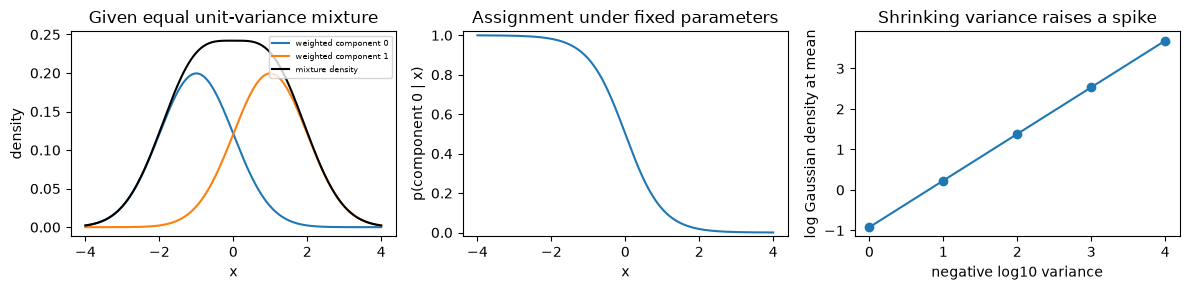

In [2]:
fig,axes = plt.subplots(1,3,figsize=(12,3))
given_axis = np.linspace(-4,4,241)
given_left = .5*np.exp(-.5*(given_axis+1)**2)/np.sqrt(2*np.pi)
given_right = .5*np.exp(-.5*(given_axis-1)**2)/np.sqrt(2*np.pi)
axes[0].plot(given_axis,given_left,label='weighted component 0')
axes[0].plot(given_axis,given_right,label='weighted component 1')
axes[0].plot(given_axis,given_left+given_right,color='black',label='mixture density')
axes[0].set(xlabel='x',ylabel='density',title='Given equal unit-variance mixture'); axes[0].legend(fontsize=6)
axes[1].plot(given_axis,1/(1+np.exp(2*given_axis)))
axes[1].set(xlabel='x',ylabel='p(component 0 | x)',title='Assignment under fixed parameters',ylim=(-.02,1.02))
given_variance = np.array([1.,.1,.01,.001,.0001])
given_at_mean = -.5*np.log(2*np.pi*given_variance)
axes[2].plot(-np.log10(given_variance),given_at_mean,marker='o')
axes[2].set(xlabel='negative log10 variance',ylabel='log Gaussian density at mean',title='Shrinking variance raises a spike')
fig.tight_layout(); plt.show()

### Exercise 03.02.11 — Compare covariance assumptions on the same observations

**Type:** Experimental · **Answer:** Code

Draw 180 training and 160 independent validation rows from the two-component mechanism below, seed 270. Fit full and diagonal covariance models with two components, floor $.02$, four starts, child-seed root 271, at most 100 steps and gain tolerance $10^{-7}$. Select each mode's run using training likelihood only. Report every status, actual elapsed time, training/validation average log density and minimum component mass. Plot responsibilities and selected likelihood traces. Interpret the comparison under its known modeling assumptions; do not redesign it repeatedly on the same validation rows and call the result a final test.

**Expected outcome:** matched-data/work-policy comparison and measured predictive scores, without an invented ranking or claim of recovering semantic classes.

In [ ]:
# Your code for Exercise 03.02.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.11**

The given component covariances are correlated in the original coordinates. A diagonal model cannot represent that conditional correlation, but finite optimization and sampling also affect the observed scores.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.11**

This uses the preceding fitter, search and E-step functions. Latent IDs are sampled to generate observations, then discarded before fitting and selection. Counts are random categorical draws in this experiment, unlike a fixed component-count design. Validation scores assess the two predeclared procedures in the same coordinate system. Their difference has sampling and optimization sensitivity; one seed is not a universal superiority claim. The actual values are printed by execution, with all tolerance/budget/failure records retained.

~~~python
from time import perf_counter

def gmm_experiment_data(seed=270):
    rng = np.random.default_rng(seed)
    weights = np.array([.6,.4]); means = np.array([[-1.,-.5],[1.2,.7]])
    covariances = np.array([[[.7,.55],[.55,.6]],[[.6,-.4],[-.4,.6]]])
    def draw(n):
        latent = rng.choice(2,n,p=weights); X = np.empty((n,2))
        for c in range(2):
            rows = latent == c
            X[rows] = rng.multivariate_normal(means[c],covariances[c],size=int(rows.sum()))
        return X
    return draw(180),draw(160)

mixture_train,mixture_validation = gmm_experiment_data()
covariance_results = {}
fig,axes = plt.subplots(1,3,figsize=(12,3.3),layout='constrained')
for axis,mode in zip(axes[:2],('full','diagonal')):
    started = perf_counter()
    model,runs,winner = gmm_restarts(mixture_train,2,starts=4,seed=271,
        covariance=mode,floor=.02,max_steps=100,tol=1e-7)
    elapsed = perf_counter()-started
    if model is None:
        raise RuntimeError('no finite fit; inspect run records: '+str(runs))
    validation_ll = gmm_e_step(mixture_validation,model)['mean_log_likelihood']
    covariance_results[mode] = dict(model=model,runs=runs,winner=winner,
        validation_mean_log_likelihood=validation_ll,seconds=elapsed)
    print(mode,dict(seconds=elapsed,training=model['mean_log_likelihood'],
        validation=validation_ll,winner=winner),runs)
    points = axis.scatter(*mixture_train.T,c=model['responsibilities'][:,0],vmin=0,vmax=1,s=12,cmap='viridis')
    axis.scatter(*model['means'].T,c='red',marker='x',s=60)
    axis.set(title=mode+' / posterior component 0',xlabel='feature 1',ylabel='feature 2')
    axes[2].plot(model['history'],label=mode)
fig.colorbar(points,ax=list(axes[:2]),label='Responsibility',shrink=.7)
axes[2].set(title='Selected run only',xlabel='EM update',ylabel='Training average log density')
axes[2].legend(); plt.show()
~~~

</details>

### Exercise 03.02.12 — Measure covariance-floor sensitivity without changing the objective mid-run

**Type:** Experimental · **Answer:** Code

For training rows $(0,0,3)$, fit two one-dimensional components using four separately declared floors $10^{-1},10^{-2},10^{-4},10^{-6}$. Initialize each feasible model at means $(0,3)$, weights $(2/3,1/3)$ and unit variances. Use at most 100 steps and tolerance $10^{-8}$. Report training and fixed-probe average log density on $(-1,.5,1.5,4)$, fitted variances, masses and stopping status. Plot both score sequences. Explain why a monotone trace at each fixed floor says nothing about comparisons across different feasible model sets.

**Expected outcome:** measured sensitivity, an explicit distribution/probe limitation, and no claim that a rising training score makes a smaller floor universally better.

In [ ]:
# Your code for Exercise 03.02.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.12**

The training sample contains duplicate values and two distinct locations. A probe between or away from those locations can be assigned very low density by a spiky fitted model.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.12**

This depends on `fit_gmm` and `gmm_e_step`. Each run holds its own floor fixed. The tiny probe is a declared stress set, not an independent identically distributed test sample or a threshold-selection oracle. Both model choice and its score units need to be reported. The plot is produced from actual executions; the general unbounded-likelihood argument concerns unconstrained Gaussian mixtures, while every fitted run here obeys a positive floor.

~~~python
floor_train = np.array([[0.],[0.],[3.]])
floor_probe = np.array([[-1.],[.5],[1.5],[4.]])
floor_initial = dict(weights=np.array([2/3,1/3]),means=np.array([[0.],[3.]]),
                     covariances=np.array([[[1.]],[[1.]]]))
floor_results = []
for variance_floor in (.1,.01,.0001,.000001):
    model = fit_gmm(floor_train,2,floor=variance_floor,initial=floor_initial,max_steps=100,tol=1e-8)
    record = dict(floor=variance_floor,training=model['mean_log_likelihood'],
        probe=gmm_e_step(floor_probe,model)['mean_log_likelihood'],
        variances=model['covariances'][:,0,0].tolist(),weights=model['weights'].tolist(),
        status=model['status'],iterations=model['iterations'],minimum_mass=model['minimum_mass'])
    floor_results.append(record); print('floor',record)
fig,axes = plt.subplots(1,2,figsize=(9,3))
horizontal = [-np.log10(record['floor']) for record in floor_results]
for axis,key,title in zip(axes,('training','probe'),('Training sample','Fixed stress probe')):
    axis.plot(horizontal,[record[key] for record in floor_results],marker='o')
    axis.set(xlabel='negative log10 variance floor',ylabel='Average log density',title=title)
fig.tight_layout(); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded primary-source study

Read [CS229 mixture notes, pp.2–3](https://see.stanford.edu/materials/aimlcs229/cs229-notes7b.pdf) and [EM notes, §2 equations (3)–(6)](https://see.stanford.edu/materials/aimlcs229/cs229-notes8.pdf) after deriving the posterior and bound. Translate their summed likelihood to this chapter's average and check the three-step ascent argument on a tiny example. The local study audits the equality condition and fixed-objective assumptions. It does not reproduce a general parameter-convergence theorem or establish recovery of the generating components.

The next variational unit restricts the family of auxiliary distributions; later generative models learn more expressive likelihoods and representations. Keep the distinction between a computable bound, observed predictive likelihood and the supported scientific claim. A more elaborate latent model does not remove the need for that distinction.

### Exercise 03.02.13 — Break the ascent claim by removing its tight E-step

**Type:** Experimental · **Answer:** Code

Use $X=(-3,3)$ with equal weights, means $(-3,3)$ and unit variances. First audit the bound at the exact posterior. Then replace it with fixed uniform categorical rows and perform the same constrained M-step with floor $.01$. Compare old/new observed likelihood, old/new bound for that fixed $q$, and KL gaps. Reproduce the selected CS229 ascent chain and identify exactly which equality fails in the modified procedure.

**Expected outcome:** a concrete case where the fixed bound improves while observed likelihood falls, and a source audit that distinguishes exact EM from an arbitrary auxiliary update.

In [ ]:
# Your code for Exercise 03.02.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.13**

Uniform rows make both new components identical, with mean zero and variance nine. That changes the equality condition at the old model.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.13**

This depends on the E-step, bound audit and M-step functions. The old model's exact posterior makes the bound tight. Uniform rows instead average a very unlikely cross-component assignment into each observation's bound. Their M-step increases that loose bound by collapsing the components onto the overall Gaussian; it need not improve the original observed density. Old average log density is $-\tfrac12\log(2\pi)+\log((1+e^{-18})/2)\approx-1.61208570$; the new identical-component value is $-\tfrac12(\log(2\pi)+\log9+1)\approx-2.51755082$. The old uniform-row bound is $-\tfrac12\log(2\pi)-9\approx-9.91893853$, which rises to the new likelihood. This finite example refutes an overbroad claim; it does not refute exact EM or all carefully controlled approximate-inference methods.

~~~python
bound_data = np.array([[-3.],[3.]])
bound_old = dict(weights=np.array([.5,.5]),means=np.array([[-3.],[3.]]),
                 covariances=np.array([[[1.]],[[1.]]]))
bound_posterior = gmm_e_step(bound_data,bound_old)['responsibilities']
bound_exact = gmm_elbo_audit(bound_data,bound_old,bound_posterior)
bound_uniform = np.full((2,2),.5)
bound_before = gmm_elbo_audit(bound_data,bound_old,bound_uniform)
bound_new = gmm_m_step(bound_data,bound_uniform,floor=.01)
bound_after = gmm_elbo_audit(bound_data,bound_new,bound_uniform)
print('exact E-step',bound_exact,'uniform before',bound_before,'uniform after',bound_after)
assert abs(bound_exact['KL_gap']) < 1e-12
assert bound_after['bound'] > bound_before['bound']
assert bound_after['mean_log_likelihood'] < bound_before['mean_log_likelihood']
~~~

</details>

### Exercise 03.02.14 — Critique confident assignments and improving training likelihood

**Type:** Critical · **Answer:** Markdown

A fit gives responsibilities near zero/one and improves training likelihood at every iteration. Explain why this does not prove semantic class recovery, parameter certainty, a globally optimal likelihood or good predictive density. Discuss component permutations, covariance assumptions, a fixed floor, optimizer starts and validation reuse.

**Expected outcome:** supported model-conditional statements and concrete missing evidence, without treating soft assignments as calibrated scientific truth.

**Your response to Exercise 03.02.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.14**

A point estimate can be confidently wrong under a misspecified model. A tiny variance can also make a training observation exceptionally likely.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.14**

Responsibilities are conditional on the fitted distribution and point-valued parameters. Permuting component IDs preserves that distribution; identical or overlapping components may be poorly identified. A monotone EM trace checks one objective and update procedure, while unconstrained covariance collapse can make likelihood unbounded. A fixed floor changes the feasible model and must be reported. Multiple starts reduce one optimization sensitivity without proving global optimality. Independent predictive scoring, sensitivity to covariance/floor assumptions and a declared selection protocol address different questions. Reusing validation outcomes for repeated redesign changes the evidence boundary. None of these measurements alone establishes natural classes, causal mechanisms or posterior certainty about parameters.

</details>

## 8. Review questions and knowledge checks

### Exercise 03.02.15 — Distinguish a zero density from floating-point underflow

**Type:** Numerical · **Answer:** Markdown

For one unit-variance Gaussian at mean zero, calculate the log density at $x=1000$. Explain why exponentiating it yields zero in float64 while the mathematical density is positive. For two equally weighted Gaussians with means zero and one, calculate the log posterior odds of component one at that observation without evaluating either raw density.

**Expected outcome:** log density $-500000-\tfrac12\log(2\pi)$ and log posterior odds $999.5$, with no fabricated impossibility claim.

**Your response to Exercise 03.02.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.15**

Subtract the two quadratic log-density expressions before exponentiation; equal log weights cancel.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.15**

The first log density is about $-500000.91893853$. It is representable even though its exponential underflows. Equal-variance log odds are $-((1000-1)^2-1000^2)/2=999.5$. A normalized posterior will round the smaller component probability to zero while its directly computed log responsibility remains finite. Keep that distinction when computing KL gaps, debugging vanished component mass and interpreting apparently certain assignments.

</details>

### Exercise 03.02.16 — Present a probabilistic-learning mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain the latent generative story, posterior, average log likelihood, KL-gap identity, constrained weighted updates, derivative conventions and stopping flags. Provide independent density/gradient/weighted-statistic/bound checks and measured covariance/floor experiments. State a conclusion the evidence still cannot support.

**Expected outcome:** explain/implement/verify/evaluate evidence, including one supported claim and one limitation of the latent explanation.

**Your response to Exercise 03.02.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.02.16**

Keep an exact inequality, a correct floating-point implementation and a scientific interpretation as separate pieces of evidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.02.16**

A complete submission derives the posterior and KL identity, implements stable density/E/M/fitting/search calculations, and documents fixed constraints and every run status. Independent scalar densities and central differences check likelihood derivatives; weighted statistics and eigenvalue cases check the M-step; an arbitrary-$q$ counterexample checks the ascent argument's assumptions. Measured held-out scoring and floor sensitivity evaluate concrete fitted procedures under declared budgets. The evidence can support those mathematical and computational contracts and conditional experimental comparisons. It cannot by itself prove global recovery, universal predictive superiority, semantic classes or certainty about all parameters.

</details>

## 9. Summary and next learning steps

Latent-variable learning requires a declared model, stable likelihoods and careful separation of observed and auxiliary objectives. EM's ascent argument depends on a tight E-step and a bound-improving update in a fixed feasible set. A covariance floor, actual stopping status and independent derivative checks make a finite implementation auditable without turning it into a global-optimality guarantee.

Before advancing, submit derivations, manual implementations, independent checks, measured covariance/floor studies and the primary-source equality-condition audit. Next: PCA and SVD, which connect representation geometry to projection, variance and reconstruction. The later Bayesian/variational chapter returns to distributional parameter estimates and restricted bounds. Return to the [stage guide](README.md) or [learning path](../../README.md); unfinished units remain planned.